<div align="center">

<h1><strong>PEMBUATAN PROMPTING STUDI KASUS GEOFISIKA</strong></h1>
<h2><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h2>


<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<h5><strong> Oleh:</strong></h5>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li>
    <strong>WAHDANIA</strong>
    <div style="margin-top:10px;">
      <strong>H061241070</strong>
    </div>
  </li>
</ul>

<p><strong>DEPARTEMEN GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong></strong></p>
<p><strong></strong></p>
<p><strong>2026</strong></p>

</div>

## **1. Pendahuluan**

Prompt yang baik pada pekerjaan geofisika berfungsi sebagai spesifikasi kerja (work specification), bukan sekadar pertanyaan singkat. Struktur yang dipakai mengikuti Gambar 2.1 (*AI Cookbook untuk Earth Sciences*), yaitu framework **R–T–C–I–K–O–Q–V**:


![Screenshot 2026-09-29 033447.png](<attachment:Screenshot 2026-09-29 033447.png>)
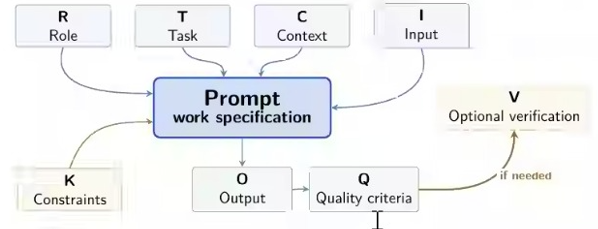

| Kode | Komponen | Fungsi |
|---|---|---|
| **R** | Role | Peran/keahlian yang dijalankan AI |
| **T** | Task | Pekerjaan spesifik yang harus dilakukan |
| **C** | Context | Latar belakang survei, lokasi, dan tujuan |
| **I** | Input | Data yang tersedia (format, jumlah, satuan) |
| **K** | Constraints | Batasan yang tidak boleh dilanggar |
| **O** | Output | Bentuk deliverable yang diminta |
| **Q** | Quality criteria | Kriteria agar output diterima |
| **V** | Optional verification | Cara memeriksa/menguji hasil (bila perlu) |

**R, T, C, I, K** membentuk *spesifikasi pekerjaan*, sedangkan **O, Q, V** membentuk *deliverable, kriteria penerimaan, dan verifikasi*.

Sesuai ketentuan tugas, pada setiap prompt di bawah:
- **Role** dan **Task** ditandai secara eksplisit (Role: kalimat perannya, Task: narasi tugasnya).
- **Output** berupa **narasi rencana keluaran** saja, belum berupa gambar/grafik jadi.

## **2. Ringkasan Lima Studi Kasus**

| No | Studi Kasus | Metode Geofisika | Tujuan Utama |
|---|---|---|---|
| 1 | Pendugaan akuifer & intrusi air laut di daerah pesisir | Geolistrik VES (Schlumberger) | Menentukan lapisan akuifer dan zona air payau/asin |
| 2 | Penentuan kedalaman batuan dasar untuk fondasi | Seismik refraksi | Menentukan ketebalan lapisan lapuk dan kedalaman *bedrock* |
| 3 | Identifikasi struktur sesar dan cekungan | Gravitasi | Memisahkan anomali regional–residual dan menafsirkan struktur |
| 4 | Pemetaan tubuh batuan ultramafik | Magnetik | Mengolah anomali magnetik (IGRF, RTP) dan menafsirkan sumber |
| 5 | Mikrozonasi tapak dan kerentanan seismik | Mikrotremor HVSR | Menentukan frekuensi dominan, amplifikasi, dan estimasi tebal sedimen |

## **3. Prompt 1 — Geolistrik VES untuk Akuifer dan Intrusi Air Laut**

Berikut contoh penerapan framework di atas untuk kasus nyata geofisika — interpretasi data *Vertical Electrical Sounding* (VES) konfigurasi Schlumberger untuk menentukan lapisan akuifer dan mendeteksi indikasi intrusi air laut di daerah pesisir menggunakan bantuan AI.

In [ ]:
prompt_1 = """
### Role
Anda bertindak sebagai ahli hidrogeofisika yang berpengalaman dalam interpretasi data geolistrik *Vertical Electrical Sounding* (VES) konfigurasi Schlumberger untuk eksplorasi air tanah di wilayah pesisir.

### Task
Interpretasikan data VES pada beberapa titik sounding untuk menentukan jumlah lapisan, resistivitas dan ketebalan tiap lapisan, mengidentifikasi lapisan yang berpotensi sebagai akuifer, serta menilai ada tidaknya indikasi intrusi air laut. Jelaskan dasar geofisis tiap kesimpulan dan bandingkan pola antar titik untuk menggambarkan variasi lateralnya dari arah pantai ke daratan.

### Context
Survei dilakukan pada suatu dataran pesisir untuk mencari sumber air bersih bagi permukiman. Kondisi geologi permukaan diduga tersusun atas endapan aluvial pantai (pasir, lempung, dan material lepas) di atas batuan dasar yang lebih kompak. Terdapat kekhawatiran bahwa sumur warga mulai terasa payau. Resistivitas rendah dapat disebabkan oleh lempung maupun air asin sehingga keduanya harus dibedakan secara hati-hati (efek ekuivalensi juga perlu diperhatikan).

### Input
- 10 titik VES pada lintasan tegak lurus garis pantai, dengan jarak antartitik sekitar 100 m
- Bentangan AB/2 dari 1,5 m sampai 150 m (±16 langkah per titik)
- File CSV berkolom: `id_titik, AB/2 (m), MN/2 (m), K, I (mA), ΔV (mV), rho_semu (Ωm)`
- Jarak tiap titik terhadap garis pantai (m)

### Constraints
- Interpretasi hanya boleh berdasar data yang diberikan; jangan menambahkan data sumur atau litologi yang tidak disediakan
- Nilai resistivitas semu tidak boleh diubah atau dihaluskan tanpa penjelasan
- Gunakan satuan baku (Ωm dan m)
- Setiap ambang resistivitas untuk klasifikasi (akuifer tawar, payau, asin, lempung) harus disebutkan dasarnya dan dinyatakan sebagai *rentang indikatif*, bukan angka pasti
- Dilarang menyimpulkan kualitas air (mis. layak minum) karena data geolistrik tidak dapat mengukurnya; cukup gunakan istilah "indikasi"
- Ketidakpastian akibat ekuivalensi harus diakui secara eksplisit

### Output
Laporan berbentuk narasi terstruktur yang berisi (1) ringkasan rentang resistivitas semu dan karakter kurva sounding secara umum; (2) deskripsi model lapisan tiap titik dalam bentuk narasi (jumlah lapisan, resistivitas, ketebalan, dan kedalaman); (3) penjelasan lapisan yang diduga akuifer beserta alasannya; (4) narasi tren perubahan resistivitas dari pantai ke daratan yang menunjukkan ada/tidaknya indikasi intrusi air laut dan sejauh mana; (5) rekomendasi lokasi pengeboran atau survei lanjutan. Gambar kurva dan penampang belum dibuat pada tahap ini; cukup dijelaskan seperti apa rencana visualisasinya.

### Quality Criteria
- Setiap klaim merujuk pada nilai resistivitas atau kedalaman tertentu dari data
- Model lapisan konsisten antartitik yang bersebelahan, dan bila berbeda, alasannya dijelaskan
- Interpretasi lempung vs air asin dibahas dengan argumen, tidak dicampuradukkan
- Tidak ada informasi yang mengada-ada di luar data input

### Optional Verification
Jika tersedia, bandingkan hasil dengan data daya hantar listrik (DHL) air sumur warga atau data log bor terdekat, dan lakukan uji sensitivitas sederhana (mis. bagaimana kesimpulan berubah bila ketebalan lapisan kedua diubah ±20%).
"""
print(prompt_1)

## **4. Prompt 2 — Seismik Refraksi untuk Kedalaman Batuan Dasar**

Berikut contoh penerapan framework di atas untuk kasus nyata geofisika — pengolahan data waktu tempuh *first-break* seismik refraksi untuk menentukan ketebalan lapisan lapuk dan kedalaman batuan dasar sebagai dasar pertimbangan fondasi jembatan menggunakan bantuan AI.


In [ ]:
prompt_2 = """
### Role
Anda bertindak sebagai geofisikawan rekayasa (*engineering geophysicist*) yang menguasai pengolahan data seismik refraksi dangkal untuk keperluan investigasi fondasi bangunan.

### Task
Olah data waktu tempuh (*first-break*) seismik refraksi untuk menentukan kecepatan gelombang P tiap lapisan, ketebalan lapisan lapuk, dan kedalaman batuan dasar sepanjang lintasan. Jelaskan langkah perhitungan yang digunakan, lalu tafsirkan implikasinya terhadap kelayakan fondasi (misalnya apakah fondasi dangkal memadai atau perlu fondasi dalam).

### Context
Lokasi rencana pembangunan sebuah jembatan kecil di area perbukitan landai. Tanah permukaan diduga berupa lapisan lapuk (tanah residual) di atas batuan yang lebih kompak. Survei dibutuhkan untuk memperkirakan kedalaman batuan dasar sebagai bahan pertimbangan desain fondasi. Diasumsikan kecepatan bertambah terhadap kedalaman sehingga metode refraksi dapat diterapkan.

### Input
- Satu lintasan sepanjang 46 m dengan 24 geophone berjarak 2 m
- 5 titik tembak (*shot point*): kedua ujung, satu titik di tengah, dan dua titik *offset*
- Tabel waktu tempuh first-break (ms) per geophone per shot point dalam format CSV
- Elevasi tiap geophone (m)

### Constraints
- Gunakan hanya waktu tempuh yang diberikan; jangan menghasilkan atau memperkirakan nilai waktu yang hilang tanpa keterangan
- Metode wajib disebutkan (*intercept-time* atau *reciprocal method*), lengkap dengan rumus yang dipakai
- Satuan konsisten (m, ms, m/s)
- Bila ada segmen dengan kecepatan yang tidak masuk akal (mis. lapisan lebih dalam lebih lambat), tandai sebagai anomali data atau kemungkinan *hidden layer*, jangan dipaksakan menjadi model
- Tidak boleh menetapkan parameter geoteknik seperti daya dukung tanah dari data kecepatan saja; cukup berikan indikasi kualitatif

### Output
Narasi laporan yang memuat (1) kualitas data dan hasil pemeriksaan first-break; (2) penjelasan pembagian segmen kurva jarak–waktu dan kecepatan tiap lapisan; (3) penjelasan model 2 atau 3 lapisan beserta ketebalan dan kedalaman *bedrock* di sepanjang lintasan (termasuk variasi topografi batuan dasar); (4) implikasi bagi fondasi; (5) daftar ketidakpastian. Grafik jarak–waktu dan penampang kecepatan cukup dijelaskan rencananya secara naratif.

### Quality Criteria
- Kecepatan dan kedalaman yang dilaporkan dapat ditelusuri kembali ke perhitungan yang ditunjukkan
- Hasil dari shot maju dan mundur konsisten (selisih waktu timbal-balik/*reciprocal time* dibahas)
- Ketidakpastian kedalaman dinyatakan dalam rentang, bukan satu angka tunggal
- Rekomendasi tidak melampaui apa yang dapat didukung data

### Optional Verification
Bandingkan kedalaman *bedrock* hasil metode dengan data bor teknik atau uji penetrasi (DCP/sondir) bila tersedia, dan bandingkan hasil *intercept-time* dengan *reciprocal method* untuk memeriksa konsistensi.
"""
print(prompt_2)

## **5. Prompt 3 — Gravitasi untuk Identifikasi Sesar dan Cekungan**

Berikut contoh penerapan framework di atas untuk kasus nyata geofisika — interpretasi data anomali Bouguer lengkap (*Complete Bouguer Anomaly*) dari survei gravitasi regional untuk mengidentifikasi sesar dan cekungan sedimen melalui pemisahan anomali regional–residual menggunakan bantuan AI.


In [ ]:
prompt_3 = """
### Role
Anda bertindak sebagai geofisikawan regional yang berpengalaman dalam pengolahan dan interpretasi data gravitasi untuk pemetaan struktur bawah permukaan.

### Task
Analisis peta anomali Bouguer lengkap (CBA) untuk memisahkan anomali regional dan residual, mengidentifikasi pola anomali yang mengindikasikan sesar dan cekungan sedimen, serta menyusun interpretasi awal struktur bawah permukaan berdasarkan kontras densitas. Jelaskan mengapa metode pemisahan yang dipilih sesuai untuk data ini.

### Context
Survei gravitasi regional dilakukan pada area seluas sekitar 20 × 20 km yang diduga memuat sebuah cekungan sedimen yang dibatasi oleh sesar normal. Batuan dasar diperkirakan memiliki densitas lebih tinggi daripada endapan sedimen di atasnya. Tujuan studi adalah memperkirakan bentuk dan kedalaman cekungan untuk kepentingan eksplorasi awal sumber daya.

### Input
- Data 150 stasiun gravitasi dengan kolom: `x, y (UTM), elevasi (m), g_observasi (mGal)`, dan nilai CBA yang sudah dikoreksi
- Rincian koreksi yang telah diterapkan (*drift*, lintang, *free-air*, Bouguer dengan densitas reduksi 2,67 g/cm³, dan medan/*terrain*)
- Estimasi kontras densitas sedimen terhadap batuan dasar (mis. −0,3 g/cm³, sebagai asumsi yang harus ditulis eksplisit)

### Constraints
- Jangan melakukan ulang koreksi gravitasi; gunakan CBA yang diberikan dan catat asumsi densitas reduksinya
- Metode pemisahan regional–residual (mis. polinomial orde rendah atau *upward continuation*) harus disebutkan beserta parameternya, dan dijelaskan pengaruh pilihan parameter terhadap hasil
- Kontras densitas hanya boleh memakai nilai input; jangan menggunakan nilai lain tanpa penjelasan
- Interpretasi struktur harus diberi label sebagai "kemungkinan" karena sifat non-unik dari solusi gravitasi
- Jangan menyatakan kedalaman cekungan tanpa menyertakan asumsi model

### Output
Laporan narasi yang berisi (1) deskripsi pola anomali Bouguer (nilai tinggi–rendah dan arah kelurusan); (2) penjelasan metode pemisahan regional–residual dan alasan pemilihannya; (3) identifikasi zona gradien horizontal tinggi yang diduga sebagai tepi sesar; (4) estimasi kasar kedalaman dan bentuk cekungan melalui model 2D sederhana (mis. satu profil melintang), dijelaskan secara narasi termasuk asumsi densitasnya; (5) keterbatasan interpretasi. Peta kontur dan profil model tidak perlu dihasilkan sekarang; cukup dijelaskan rencana tampilannya.

### Quality Criteria
- Setiap zona anomali disebut dengan posisi dan besar amplitudo dalam mGal
- Hasil interpretasi konsisten antara peta residual, gradien horizontal, dan profil model
- Sifat non-unik (ambiguitas) gravitasi dibahas secara jelas
- Tidak ada penambahan data geologi yang tidak diberikan

### Optional Verification
Bandingkan lokasi sesar hasil interpretasi dengan peta geologi atau data seismik regional bila ada, dan uji sensitivitas terhadap variasi kontras densitas (mis. ±0,1 g/cm³) untuk melihat perubahan estimasi kedalaman.
"""
print(prompt_3)

## **6. Prompt 4 — Magnetik untuk Pemetaan Tubuh Batuan Ultramafik**

Berikut contoh penerapan framework di atas untuk kasus nyata geofisika — pengolahan dan interpretasi data magnetik total (koreksi IGRF dan *Reduction to Pole*) di wilayah lintang rendah untuk memetakan sebaran tubuh batuan ultramafik menggunakan bantuan AI.

In [ ]:
prompt_4 = """
### Role
Anda bertindak sebagai geofisikawan eksplorasi yang berpengalaman dalam pengolahan dan interpretasi data magnetik di wilayah lintang rendah.

### Task
Olah data intensitas medan magnet total menjadi anomali magnetik (koreksi harian dan pengurangan IGRF), terapkan reduksi ke kutub (RTP) dengan pertimbangan kondisi lintang rendah, lalu tafsirkan sebaran tubuh sumber anomali yang diduga batuan ultramafik terserpentinisasi, termasuk posisi, kemenerusan, dan tingkat keyakinan interpretasinya.

### Context
Survei magnetik darat dilakukan pada area berbukit yang secara regional dikenal memuat kompleks batuan ultramafik. Batuan tersebut umumnya memiliki suseptibilitas magnetik lebih tinggi daripada batuan sekitarnya. Karena area berada di lintang rendah dengan inklinasi medan yang kecil, anomali bersifat dipolar dan RTP dapat menghasilkan artefak yang perlu diwaspadai.

### Input
- Data 400 titik pengukuran dengan kolom: `x, y (UTM), elevasi (m), waktu, T_observasi (nT)`
- Data variasi harian dari stasiun basis
- Parameter IGRF lokal (nilai ilustratif: inklinasi sekitar −20°, deklinasi sekitar 1°, sebagai contoh yang harus disesuaikan dengan tanggal dan lokasi survei)

### Constraints
- Jangan mengubah nilai observasi mentah; setiap koreksi harus dicatat dan dijelaskan
- Nilai IGRF dan parameter RTP harus disebutkan dan tidak boleh diganti secara diam-diam
- Jelaskan risiko RTP pada lintang rendah dan tawarkan alternatif pembanding (mis. sinyal analitik atau RTE/*reduction to equator*) sebagai pembanding, bukan sebagai pengganti tanpa alasan
- Tidak boleh menyimpulkan jenis batuan atau mineral secara pasti; hanya boleh menyebutnya "diduga/berindikasi"
- Jangan menetapkan suseptibilitas nyata tanpa data pengukuran; bila diberikan estimasi, tandai sebagai asumsi

### Output
Narasi laporan yang memuat (1) ringkasan alur koreksi data dan hasil anomali magnetik total (rentang nilai dalam nT); (2) penjelasan efek inklinasi rendah terhadap bentuk anomali; (3) deskripsi hasil RTP dan perbandingannya dengan sinyal analitik; (4) daftar zona anomali yang diduga tubuh ultramafik dengan posisi, arah kemenerusan, dan tingkat keyakinan (tinggi/sedang/rendah); (5) saran survei lanjutan. Peta anomali yang dihasilkan nanti cukup digambarkan secara naratif terlebih dahulu.

### Quality Criteria
- Setiap zona anomali didukung amplitudo dan luasan yang terukur dari data
- Perbedaan hasil RTP dan sinyal analitik dijelaskan, bukan diabaikan
- Batas antara fakta data dan dugaan geologi dinyatakan dengan jelas
- Satuan konsisten (nT, m)

### Optional Verification
Bandingkan posisi anomali dengan peta geologi permukaan atau singkapan yang diketahui, dan bila ada, dengan data suseptibilitas sampel batuan atau data gravitasi untuk menguji kesesuaian densitas–suseptibilitas.
"""
print(prompt_4)

## **7. Prompt 5 — Mikrotremor HVSR untuk Mikrozonasi Tapak**

Berikut contoh penerapan framework di atas untuk kasus nyata geofisika — analisis data mikrotremor dengan metode *Horizontal-to-Vertical Spectral Ratio* (HVSR) untuk menentukan frekuensi dominan, amplifikasi, dan kerentanan seismik dalam mikrozonasi tapak menggunakan bantuan AI.

In [ ]:
prompt_5 = """
### Role
Anda bertindak sebagai seismolog rekayasa (*engineering seismologist*) yang berpengalaman dalam analisis rasio spektral horizontal terhadap vertikal (HVSR) dari data mikrotremor untuk studi respons tapak.

### Task
Analisis kurva HVSR dari sejumlah titik pengukuran untuk menentukan frekuensi dominan (f₀) dan amplitudo puncak (A₀) tiap titik, memeriksa kelayakan puncak berdasarkan kriteria SESAME, memperkirakan ketebalan sedimen, dan mengelompokkan titik-titik ke dalam zona kerentanan relatif terhadap guncangan gempa.

### Context
Studi dilakukan di sebuah kawasan permukiman yang berada di atas endapan aluvial dan dekat dengan zona sesar aktif. Tujuannya adalah mikrozonasi awal untuk mengetahui bagian kawasan yang berpotensi mengalami amplifikasi guncangan lebih besar akibat sedimen lunak. Diasumsikan kontras impedansi yang cukup antara sedimen dan batuan dasar sehingga puncak HVSR dapat diinterpretasikan.

### Input
- 20 titik pengukuran mikrotremor, tiap titik direkam 30 menit dengan seismometer 3 komponen, laju sampling 100 Hz
- Untuk tiap titik: file rekaman (format `.mseed` atau `.txt`) atau hasil kurva HVSR berupa tabel frekuensi–rasio H/V
- Koordinat titik dan catatan kondisi lapangan (cuaca, gangguan lalu lintas, dll.)
- Estimasi kecepatan gelombang geser rata-rata sedimen, Vs (m/s), bila tersedia

### Constraints
- Parameter pengolahan (panjang jendela, *anti-triggering*, *smoothing*) harus disebutkan dan tidak diubah antartitik tanpa alasan
- Rumus tebal sedimen h = Vs / (4·f₀) hanya boleh dipakai bila Vs diberikan; jika tidak, sebutkan sebagai asumsi dengan rentang nilai dan jangan disajikan sebagai hasil pasti
- Puncak yang tidak lolos kriteria SESAME harus ditandai "tidak jelas/tidak andal", tidak boleh dipaksakan menjadi hasil
- Indeks kerentanan (mis. Kg = A₀²/f₀) hanya sebagai indikator relatif antar titik, bukan prediksi kerusakan
- Dilarang menyimpulkan tingkat kerusakan gempa secara pasti

### Output
Narasi laporan yang berisi (1) ringkasan kualitas data dan titik yang dikeluarkan beserta alasannya; (2) tabel naratif f₀ dan A₀ tiap titik dan status kelayakan puncak; (3) penjelasan estimasi ketebalan sedimen dan asumsi Vs yang dipakai; (4) pengelompokan zona (kerentanan tinggi, sedang, rendah) dengan penjelasan pola sebarannya terhadap kondisi geologi dan sesar; (5) rekomendasi (mis. titik yang perlu pengukuran ulang atau metode pendukung seperti MASW). Peta zonasi belum dibuat; cukup diuraikan rencana tampilannya.

### Quality Criteria
- f₀ dan A₀ tiap titik dapat ditelusuri ke kurva HVSR yang diberikan
- Semua asumsi (Vs, ambang zonasi) dinyatakan eksplisit
- Ketidakpastian ketebalan sedimen dinyatakan dalam rentang
- Pola zonasi konsisten dengan sebaran f₀ dan A₀, bukan dengan asumsi di luar data

### Optional Verification
Bandingkan ketebalan sedimen dengan data bor atau geolistrik, dan bandingkan Vs asumsi dengan hasil MASW atau data Vs30 bila tersedia.
"""
print(prompt_5)

## **8. Mengapa Kelima Prompt Ini Dianggap Baik**

- **Role** spesifik pada subdisiplin (hidrogeofisika, seismik rekayasa, dst.), sehingga AI menjawab dengan sudut pandang dan tingkat teknis yang tepat.
- **Task** memakai kata kerja terukur (interpretasikan, olah, analisis, tentukan, kelompokkan) dan menjelaskan hasil akhir yang diharapkan.
- **Context** memuat kondisi geologi, tujuan studi, dan masalah nyata, sehingga jawaban tidak generik.
- **Input** menyebut format, jumlah data, dan satuan sehingga AI tahu apa yang tersedia dan tidak tersedia.
- **Constraints** mencegah AI mengarang data, memaksakan kesimpulan, atau menyatakan hal yang tidak bisa dibuktikan metode terkait (mis. kualitas air dari geolistrik).
- **Output** berupa narasi rencana keluaran yang terstruktur, sesuai ketentuan tugas (belum berupa gambar).
- **Quality Criteria** menjadi tolok ukur objektif untuk menerima atau menolak jawaban AI.
- **Optional Verification** memberi cara menguji hasil dengan data pembanding dan uji sensitivitas.

## 9. Catatan Penutup

Kelima prompt di atas dapat dipersingkat bila detailnya telah tersimpan pada *configuration* atau *recipe* pendamping, tetapi komponen **Constraints** dan **Quality Criteria** tidak boleh hilang karena keduanya menjadi kontrak kerja antara pengguna dan AI. Nilai-nilai angka pada bagian Input (jumlah titik, spasi, parameter) merupakan contoh ilustratif dan perlu disesuaikan dengan data survei yang sebenarnya.